In [440]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.decomposition import PCA
import seaborn as sns

In [441]:

df = pd.read_csv("Dataset/Mall_Customers.csv")
print("First 10 rows:")
print(df.head(10))
print("\nShape:", df.shape)
print("\nData types:")
print(df.info())
print("\nMissing values:")
print(df.isnull().sum())

First 10 rows:
   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
5           6  Female   22                  17                      76
6           7  Female   35                  18                       6
7           8  Female   23                  18                      94
8           9    Male   64                  19                       3
9          10  Female   30                  19                      72

Shape: (200, 5)

Data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------       

In [442]:
features = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df[features]

In [443]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [444]:
k_values = [2, 3, 5]
sil_scores = {}

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    df[f"K{k}_Label"] = labels
    sil = silhouette_score(X_scaled, labels)
    sil_scores[k] = sil
    print(f"K={k}: Silhouette Score = {sil:.4f}")

K=2: Silhouette Score = 0.3213
K=3: Silhouette Score = 0.4666
K=5: Silhouette Score = 0.5547


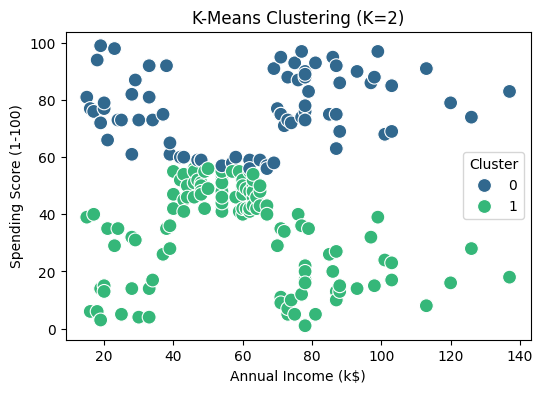

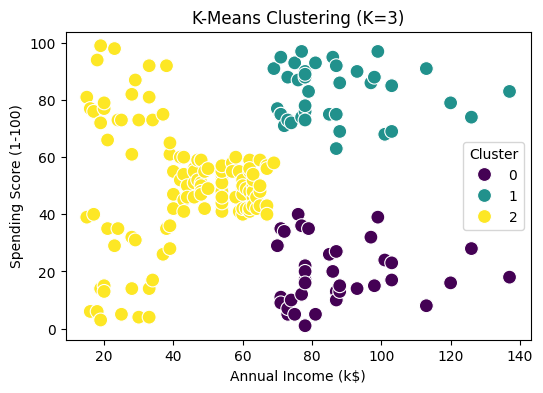

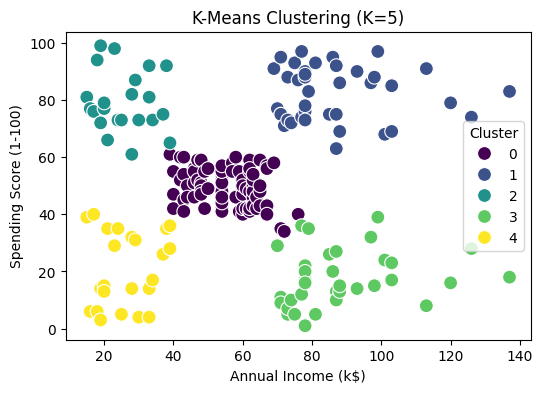

In [445]:
for k in k_values:
    plt.figure(figsize=(6, 4))
    sns.scatterplot(data=df, x=features[0], y=features[1], hue=f"K{k}_Label", palette='viridis', s=100)
    plt.xlabel(features[0])
    plt.ylabel(features[1])
    plt.title(f"K-Means Clustering (K={k})")
    plt.legend(title='Cluster')
    plt.show()

In [447]:
best_k = max(sil_scores, key=sil_scores.get)
km_best = KMeans(n_clusters=best_k, random_state=42, n_init=10)
labels_best = km_best.fit_predict(X_scaled)
df["BestK_Label"] = labels_best

In [448]:

centers_scaled = km_best.cluster_centers_
centers_original = scaler.inverse_transform(centers_scaled)
cluster_centers = pd.DataFrame(centers_original, columns=features)
cluster_centers["Cluster"] = cluster_centers.index

print(f"\nBest K: {best_k}")
print("\nCluster Centers:")
print(cluster_centers)


Best K: 5

Cluster Centers:
   Annual Income (k$)  Spending Score (1-100)  Cluster
0           55.296296               49.518519        0
1           86.538462               82.128205        1
2           25.727273               79.363636        2
3           88.200000               17.114286        3
4           26.304348               20.913043        4


In [449]:
print("\nCluster Descriptions:")
mean_income = df[features[0]].mean()
mean_spending = df[features[1]].mean()

for i, row in cluster_centers.iterrows():
    income = row[features[0]]
    spending = row[features[1]]
    
    if income < mean_income and spending > mean_spending:
        desc = "low income, high spending"
    elif income < mean_income and spending < mean_spending:
        desc = "low income, low spending"
    elif income > mean_income and spending > mean_spending:
        desc = "high income, high spending"
    elif income > mean_income and spending < mean_spending:
        desc = "high income, low spending"
    else:
        desc = "medium income, medium spending"
    
    print(f"Cluster {i}: {desc} (Income: ${income:.1f}k, Spending: {spending:.1f})")


Cluster Descriptions:
Cluster 0: low income, low spending (Income: $55.3k, Spending: 49.5)
Cluster 1: high income, high spending (Income: $86.5k, Spending: 82.1)
Cluster 2: low income, high spending (Income: $25.7k, Spending: 79.4)
Cluster 3: high income, low spending (Income: $88.2k, Spending: 17.1)
Cluster 4: low income, low spending (Income: $26.3k, Spending: 20.9)


In [450]:
df = pd.read_csv("Dataset/Mall_Customers.csv")

In [451]:
features = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df[features]

In [452]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

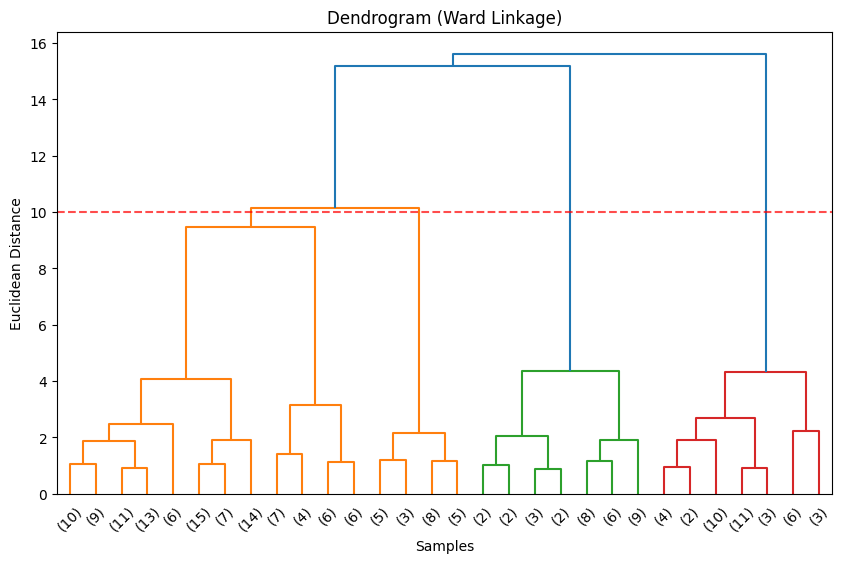

In [453]:
linked = linkage(X_scaled, method='ward')
plt.figure(figsize=(10, 6))
dendrogram(linked, orientation='top', distance_sort='descending', show_leaf_counts=True, truncate_mode='lastp', p=30)
plt.title("Dendrogram (Ward Linkage)")
plt.xlabel("Samples")
plt.ylabel("Euclidean Distance")
plt.axhline(y=10, color='r', linestyle='--', alpha=0.7)
plt.show()


In [454]:
n_clusters = 5
hc = AgglomerativeClustering(n_clusters=n_clusters, linkage='ward')
df["HC_Label"] = hc.fit_predict(X_scaled)
print(f"\nCluster counts (Hierarchical, n_clusters={n_clusters}):")
print(df["HC_Label"].value_counts().sort_index())


Cluster counts (Hierarchical, n_clusters=5):
HC_Label
0    32
1    39
2    85
3    21
4    23
Name: count, dtype: int64


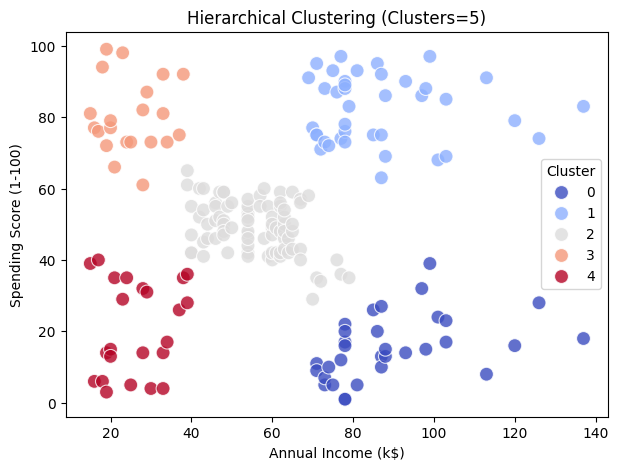

In [455]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x=features[0], y=features[1], hue="HC_Label", palette='coolwarm', s=100, alpha=0.8)
plt.xlabel(features[0])
plt.ylabel(features[1])
plt.title(f"Hierarchical Clustering (Clusters={n_clusters})")
plt.legend(title='Cluster')
plt.show()

In [456]:
df = pd.read_csv("Dataset/Iris.csv")

print("First 10 rows:")
print(df.head(10))
print("\nShape:", df.shape)
print("\nSummary statistics:")
print(df.describe())
print("\nMissing values:")
print(df.isnull().sum())

First 10 rows:
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
0   1            5.1           3.5            1.4           0.2
1   2            4.9           3.0            1.4           0.2
2   3            4.7           3.2            1.3           0.2
3   4            4.6           3.1            1.5           0.2
4   5            5.0           3.6            1.4           0.2
5   6            5.4           3.9            1.7           0.4
6   7            4.6           3.4            1.4           0.3
7   8            5.0           3.4            1.5           0.2
8   9            4.4           2.9            1.4           0.2
9  10            4.9           3.1            1.5           0.1

Shape: (150, 5)

Summary statistics:
               Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
count  150.000000     150.000000    150.000000     150.000000    150.000000
mean    75.500000       5.843333      3.054000       3.758667      1.198667
std     43.4453

In [457]:
df = df.drop('Id', axis=1)
numeric_cols = ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']
X = df[numeric_cols]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [458]:
pca_2 = PCA(n_components=2)
principal_components_2 = pca_2.fit_transform(X_scaled)
pca_df_2 = pd.DataFrame(principal_components_2, columns=['PC1', 'PC2'])

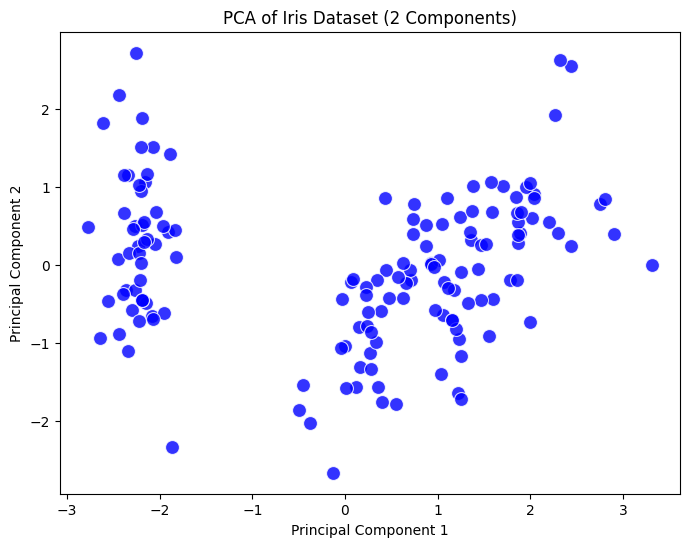

In [459]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=pca_df_2, x='PC1', y='PC2', color='blue', s=100, alpha=0.8)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA of Iris Dataset (2 Components)')
plt.show()

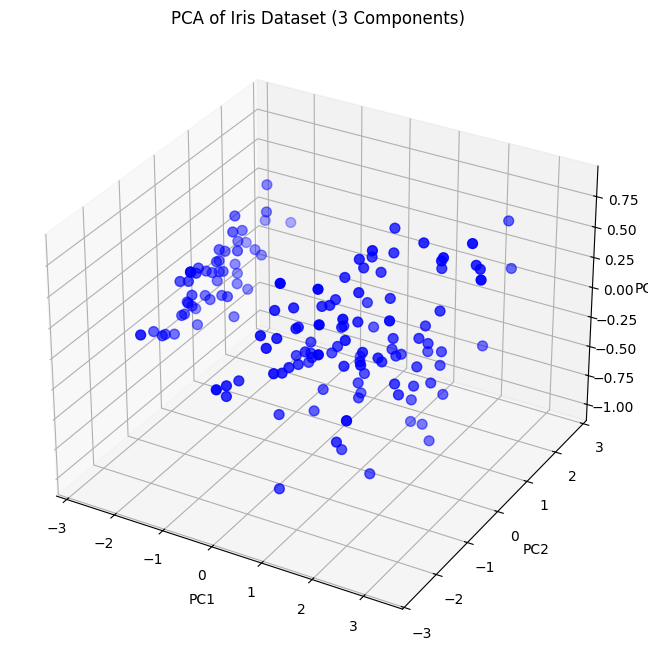

In [460]:
pca_3 = PCA(n_components=3)
principal_components_3 = pca_3.fit_transform(X_scaled)
pca_df_3 = pd.DataFrame(principal_components_3, columns=['PC1', 'PC2', 'PC3'])

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(pca_df_3['PC1'], pca_df_3['PC2'], pca_df_3['PC3'], color='blue', s=50)
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
ax.set_title('PCA of Iris Dataset (3 Components)')
plt.show()

In [461]:
print("\nPCA with 2 Components")
explained_var_2 = pca_2.explained_variance_ratio_
for i, var in enumerate(explained_var_2, start=1):
    print(f"PC{i}: {var:.4f}")
print(f"Cumulative variance: {explained_var_2.sum():.4f}")

print("\nPCA with 3 Components")
explained_var_3 = pca_3.explained_variance_ratio_
for i, var in enumerate(explained_var_3, start=1):
    print(f"PC{i}: {var:.4f}")
print(f"Cumulative variance: {explained_var_3.sum():.4f}")


PCA with 2 Components
PC1: 0.7277
PC2: 0.2303
Cumulative variance: 0.9580

PCA with 3 Components
PC1: 0.7277
PC2: 0.2303
PC3: 0.0368
Cumulative variance: 0.9948
